<h1>Phân tích khám phá dữ liệu (EDA) – RT-IoT2022</h1>

# **Giới thiệu**

Bộ dữ liệu **RT-IoT2022** ghi lại lưu lượng mạng của các thiết bị IoT, gồm cả hoạt động bình thường và các kiểu tấn công.

- 123.117 dòng, 84 cột (đặc trưng của luồng mạng: thời lượng, số gói, kích thước header, cờ TCP, ...)
- 2 cột phân loại: `proto`, `service`
- Nhãn `Attack_type` có 12 lớp

**Mục tiêu:** EDA ban đầu bằng pandas, matplotlib và seaborn.

In [1]:
# importing pandas, and other necessary modules
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np

# **Đọc dữ liệu**

Vì có 84 cột, chỉ chọn vài cột đại diện (`cols`) và lấy mẫu 2.000 dòng (`sample`) cho các biểu đồ nặng.

In [2]:
df = pd.read_csv('../data/RT_IOT2022', index_col=0)
cols = ['flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'flow_pkts_per_sec', 'Attack_type']  # 84 cột quá nhiều để vẽ, chọn vài cột đại diện
sample = df[cols].sample(2000, random_state=0)  # lấy mẫu cho biểu đồ nặng

# **Tổng quan dữ liệu (không dùng biểu đồ)**

In [3]:
df

,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2005,59247,63331,tcp,-,0.000006,1,1,0,0,167772.160000,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1024,0,1024,NMAP_XMAS_TREE_SCAN
2006,59247,64623,tcp,-,0.000007,1,1,0,0,144631.172414,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1024,0,1024,NMAP_XMAS_TREE_SCAN
2007,59247,64680,tcp,-,0.000006,1,1,0,0,167772.160000,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1024,0,1024,NMAP_XMAS_TREE_SCAN
2008,59247,65000,tcp,-,0.000006,1,1,0,0,167772.160000,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1024,0,1024,NMAP_XMAS_TREE_SCAN


In [4]:
df.shape

(123117, 84)

In [5]:
df.head()

,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


Kiểu dữ liệu của các cột

In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 123117 entries, 0 to 2009
Data columns (total 84 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   id.orig_p                 123117 non-null  int64  
 1   id.resp_p                 123117 non-null  int64  
 2   proto                     123117 non-null  str    
 3   service                   123117 non-null  str    
 4   flow_duration             123117 non-null  float64
 5   fwd_pkts_tot              123117 non-null  int64  
 6   bwd_pkts_tot              123117 non-null  int64  
 7   fwd_data_pkts_tot         123117 non-null  int64  
 8   bwd_data_pkts_tot         123117 non-null  int64  
 9   fwd_pkts_per_sec          123117 non-null  float64
 10  bwd_pkts_per_sec          123117 non-null  float64
 11  flow_pkts_per_sec         123117 non-null  float64
 12  down_up_ratio             123117 non-null  float64
 13  fwd_header_size_tot       123117 non-null  int64  
 14  fwd_he

Kiểm tra giá trị thiếu

In [7]:
df.isnull().sum()

id.orig_p               0
id.resp_p               0
proto                   0
service                 0
flow_duration           0
                       ..
idle.std                0
fwd_init_window_size    0
bwd_init_window_size    0
fwd_last_window_size    0
Attack_type             0
Length: 84, dtype: int64

**Thống kê mô tả các biến số**

In [8]:
df.describe()

,id.orig_p,id.resp_p,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,...,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size
count,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,1.231170e+05,1.231170e+05,1.231170e+05,...,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,123117.000000,123117.000000,123117.000000
mean,34639.258738,1014.305092,3.809566,2.268826,1.909509,1.471218,0.820260,3.518063e+05,3.517620e+05,7.035683e+05,...,1.481354e+05,2.353599e+04,1.616655e+06,1.701956e+06,3.517644e+06,1.664985e+06,4.550183e+04,6118.905123,2739.776018,751.647514
std,19070.620354,5256.371994,130.005408,22.336565,33.018311,19.635196,32.293948,3.707645e+05,3.708015e+05,7.415634e+05,...,1.613007e+06,1.477935e+06,8.809396e+06,9.252337e+06,1.229508e+08,9.007064e+06,1.091361e+06,18716.313861,10018.848534,6310.183843
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,17702.000000,21.000000,0.000001,1.000000,1.000000,1.000000,0.000000,7.454354e+01,7.288927e+01,1.490871e+02,...,9.536740e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
50%,37221.000000,21.000000,0.000004,1.000000,1.000000,1.000000,0.000000,2.467238e+05,2.467238e+05,4.934475e+05,...,4.053116e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
75%,50971.000000,21.000000,0.000005,1.000000,1.000000,1.000000,0.000000,5.242880e+05,5.242880e+05,1.048576e+06,...,5.006790e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
max,65535.000000,65389.000000,21728.335578,4345.000000,10112.000000,4345.000000,10105.000000,1.048576e+06,1.048576e+06,2.097152e+06,...,4.374931e+08,4.774862e+08,3.000000e+08,3.000000e+08,2.096777e+10,3.000000e+08,1.208029e+08,65535.000000,65535.000000,65535.000000


## Các lớp (`Attack_type`) có cân bằng không?

In [9]:
df['Attack_type'].value_counts()

Attack_type
DOS_SYN_Hping                 94659
Thing_Speak                    8108
ARP_poisioning                 7750
MQTT_Publish                   4146
NMAP_UDP_SCAN                  2590
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  534
Wipro_bulb                      253
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    28
Name: count, dtype: int64

## Tương quan giữa các biến

In [10]:
df.corr(numeric_only=True)

,id.orig_p,id.resp_p,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,...,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size
id.orig_p,1.000000,0.168818,0.019978,0.040027,0.021090,0.017724,0.017749,-0.095665,-0.095754,-0.095710,...,0.049005,0.003530,0.120457,0.120340,0.019328,0.121083,0.028181,0.206620,0.178322,0.075855
id.resp_p,0.168818,1.000000,0.012719,0.005481,-0.004072,0.001625,-0.001290,-0.135708,-0.135704,-0.135707,...,0.005556,-0.000370,0.022867,0.022367,0.012528,0.022665,0.000354,0.036895,-0.011118,0.128522
flow_duration,0.019978,0.012719,1.000000,0.741707,0.071395,0.754355,0.058859,-0.027805,-0.027799,-0.027802,...,0.059808,0.041024,0.091827,0.136132,0.995023,0.123398,0.112170,0.057173,0.060731,0.003591
fwd_pkts_tot,0.040027,0.005481,0.741707,1.000000,0.407452,0.914683,0.379742,-0.053855,-0.053875,-0.053865,...,0.218544,0.186920,0.087095,0.120481,0.710351,0.106671,0.115612,0.132710,0.147478,0.008330
bwd_pkts_tot,0.021090,-0.004072,0.071395,0.407452,1.000000,0.094172,0.992956,-0.026131,-0.026121,-0.026126,...,0.045700,0.042725,0.043270,0.070579,0.071428,0.059080,0.107515,0.079270,0.104156,0.012885
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
idle.avg,0.121083,0.022665,0.123398,0.106671,0.059080,0.040036,0.046673,-0.175402,-0.175363,-0.175383,...,0.206737,0.023730,0.992706,0.995069,0.126592,1.000000,0.243595,0.554487,0.498399,-0.000748
idle.std,0.028181,0.000354,0.112170,0.115612,0.107515,0.051228,0.094403,-0.039561,-0.039552,-0.039557,...,0.026651,0.042978,0.136860,0.327387,0.115919,0.243595,1.000000,0.115768,0.163924,0.004764
fwd_init_window_size,0.206620,0.036895,0.057173,0.132710,0.079270,0.035651,0.053777,-0.274301,-0.274652,-0.274478,...,0.246291,0.031844,0.552291,0.550056,0.056422,0.554487,0.115768,1.000000,0.834001,0.323171
bwd_init_window_size,0.178322,-0.011118,0.060731,0.147478,0.104156,0.046718,0.072643,-0.259457,-0.259403,-0.259431,...,0.219481,0.049145,0.488590,0.499738,0.060308,0.498399,0.163924,0.834001,1.000000,-0.002234


# **EDA bằng biểu đồ**

Tiếp tục các câu hỏi ở phần trên, nhưng trả lời bằng biểu đồ.

## **Phân bố các lớp**

Dùng thang log vì số lượng giữa các lớp chênh lệch rất lớn.

### Dùng pandas

<Axes: xlabel='Attack_type'>

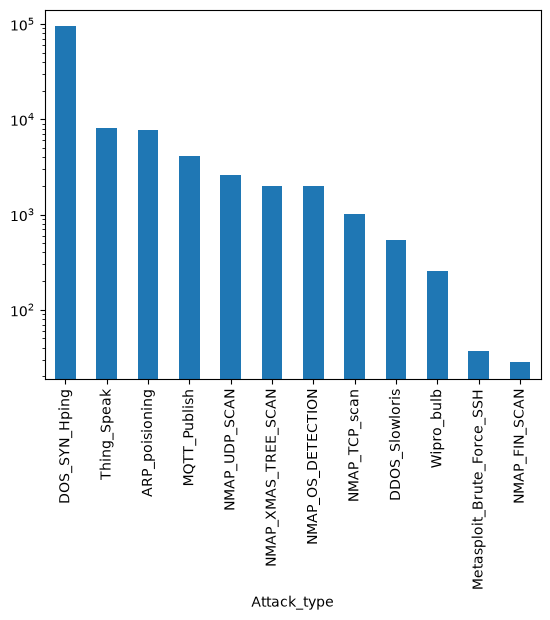

In [11]:
df["Attack_type"].value_counts().plot.bar(logy=True)  # lớp lệch nặng -> thang log

### Dùng matplotlib

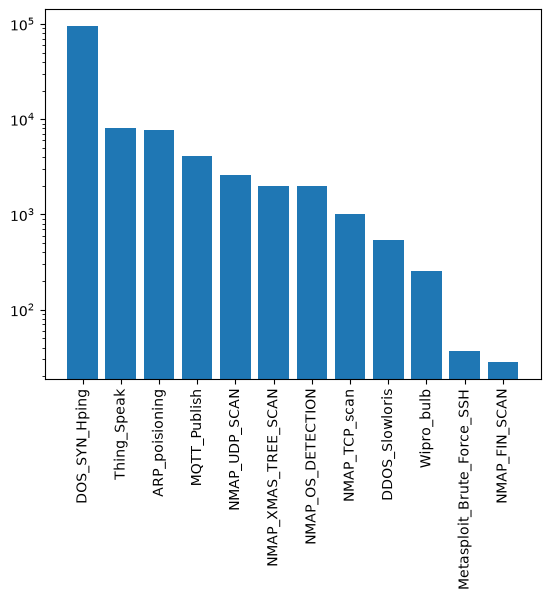

In [12]:
#we can use bar chart
counts = df["Attack_type"].value_counts()
plt.bar(counts.index, counts.values); plt.yscale('log'); plt.xticks(rotation=90);

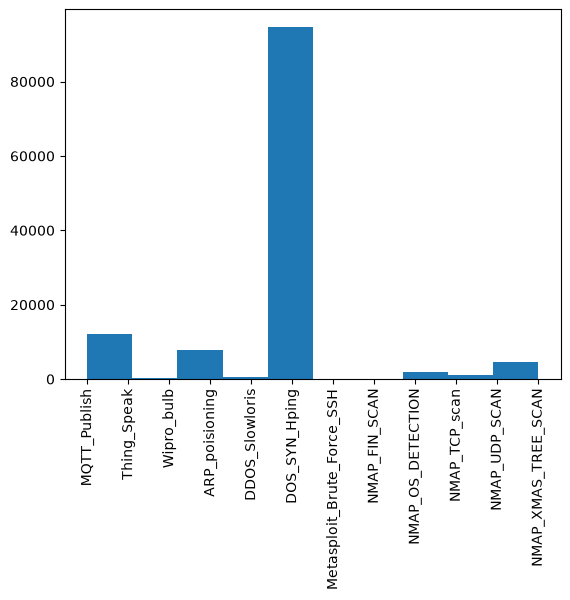

In [13]:
#one way using histogram :)
plt.hist(df['Attack_type']); plt.xticks(rotation=90);

### Dùng seaborn

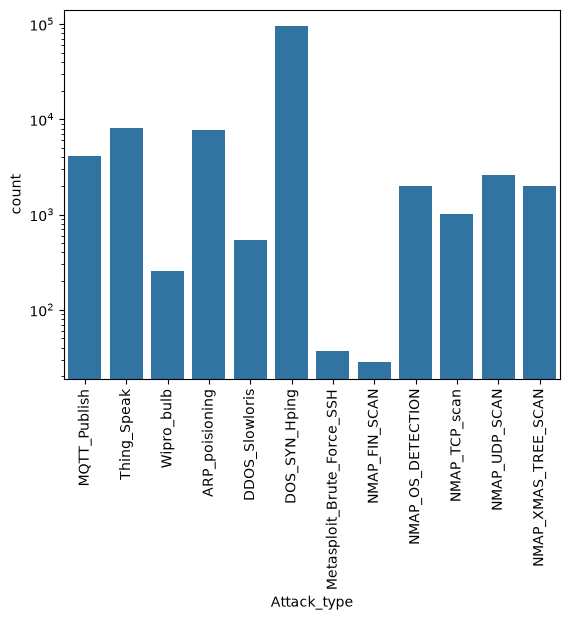

In [14]:
sns.countplot(x = df['Attack_type']); plt.yscale('log'); plt.xticks(rotation=90);

### Nhận xét:

- Dữ liệu **mất cân bằng nặng**: `DOS_SYN_Hping` chiếm ~77% (94.659 dòng), trong khi `NMAP_FIN_SCAN` chỉ có 28 dòng.
- Không nên chỉ dùng accuracy; cần F1 (macro), precision/recall theo từng lớp.
- Cần xử lý mất cân bằng: oversampling (SMOTE), undersampling hoặc class weight.

## **Biểu đồ so sánh**

### Scatterplot

Biểu diễn quan hệ giữa hai biến số trên hệ trục tọa độ.

Ví dụ: quan hệ giữa `flow_duration` (thời lượng luồng) và `fwd_pkts_tot` (tổng số gói gửi đi).

### Dùng pandas

<Axes: xlabel='flow_duration', ylabel='fwd_pkts_tot'>

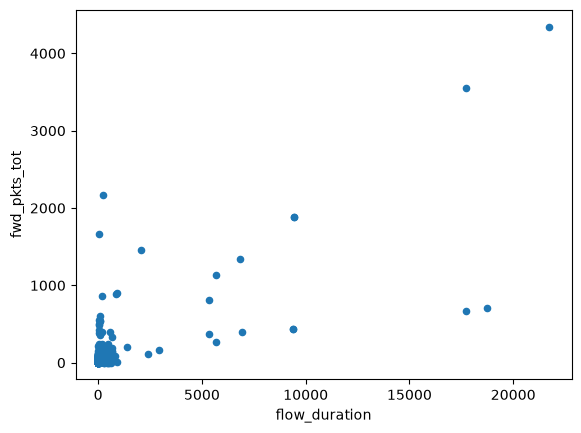

In [15]:
df.plot.scatter('flow_duration','fwd_pkts_tot')

### Dùng matplotlib

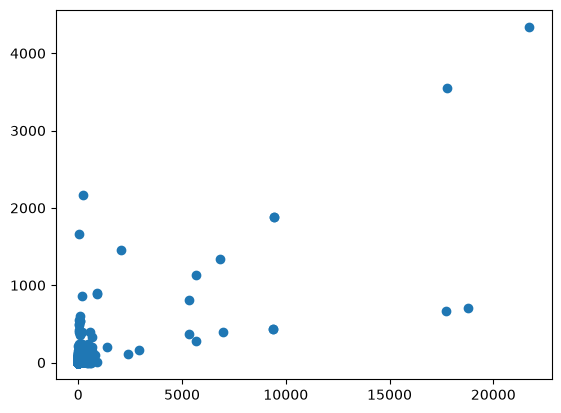

In [16]:
plt.scatter('flow_duration', 'fwd_pkts_tot', data=df)

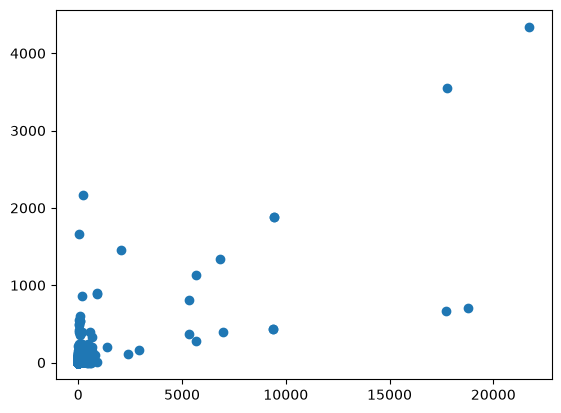

In [17]:
plt.scatter(df['flow_duration'], df['fwd_pkts_tot'])

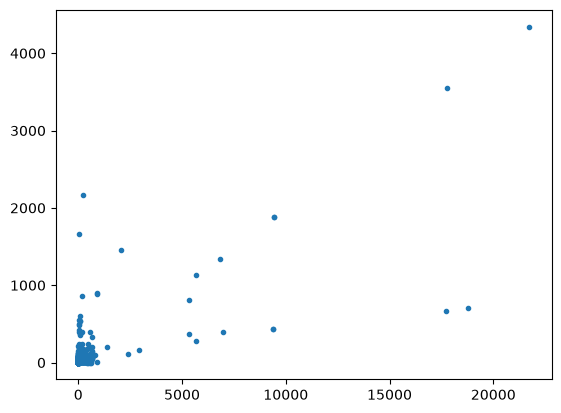

In [18]:
#using plt
plt.plot('flow_duration', 'fwd_pkts_tot', data=df, marker='.',linestyle='none')

### Dùng seaborn

<Axes: xlabel='flow_duration', ylabel='fwd_pkts_tot'>

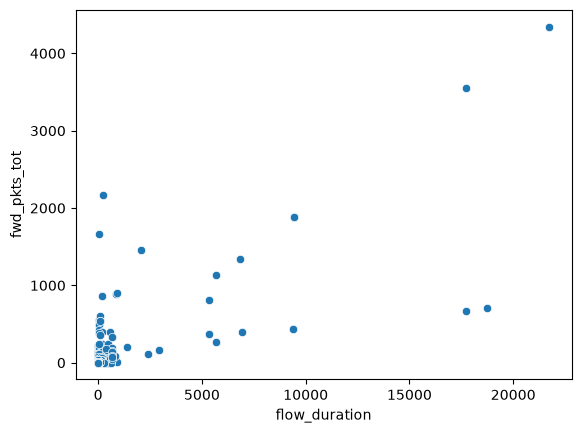

In [19]:
sns.scatterplot(x = df['flow_duration'], y = df['fwd_pkts_tot'])
#or sns.scatter('flow_duration', 'fwd_pkts_tot', data=df)

<Axes: xlabel='flow_duration', ylabel='fwd_pkts_tot'>

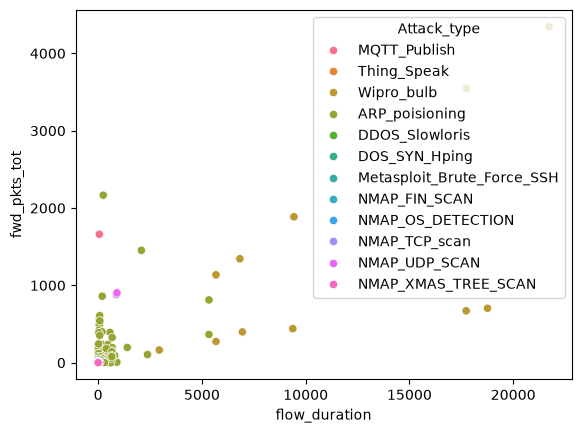

In [20]:
# With respect to the target class (Attack_type)
sns.scatterplot(x = 'flow_duration', y = 'fwd_pkts_tot', hue=df['Attack_type'], data=df)

### Nhận xét:

- Phần lớn điểm dồn sát gốc tọa độ: trung vị `flow_duration` ≈ 0 giây, `fwd_pkts_tot` = 1, nhưng giá trị lớn nhất lên tới 21.728 giây và 4.345 gói → phân phối **lệch phải, nhiều outlier**.
- Nên dùng thang log hoặc chuẩn hóa trước khi mô hình hóa.

*Từ đây trở đi chỉ dùng seaborn.*

## **Pairplot**

Xem quan hệ từng cặp biến số (trên mẫu 2.000 dòng, các cột trong `cols`).

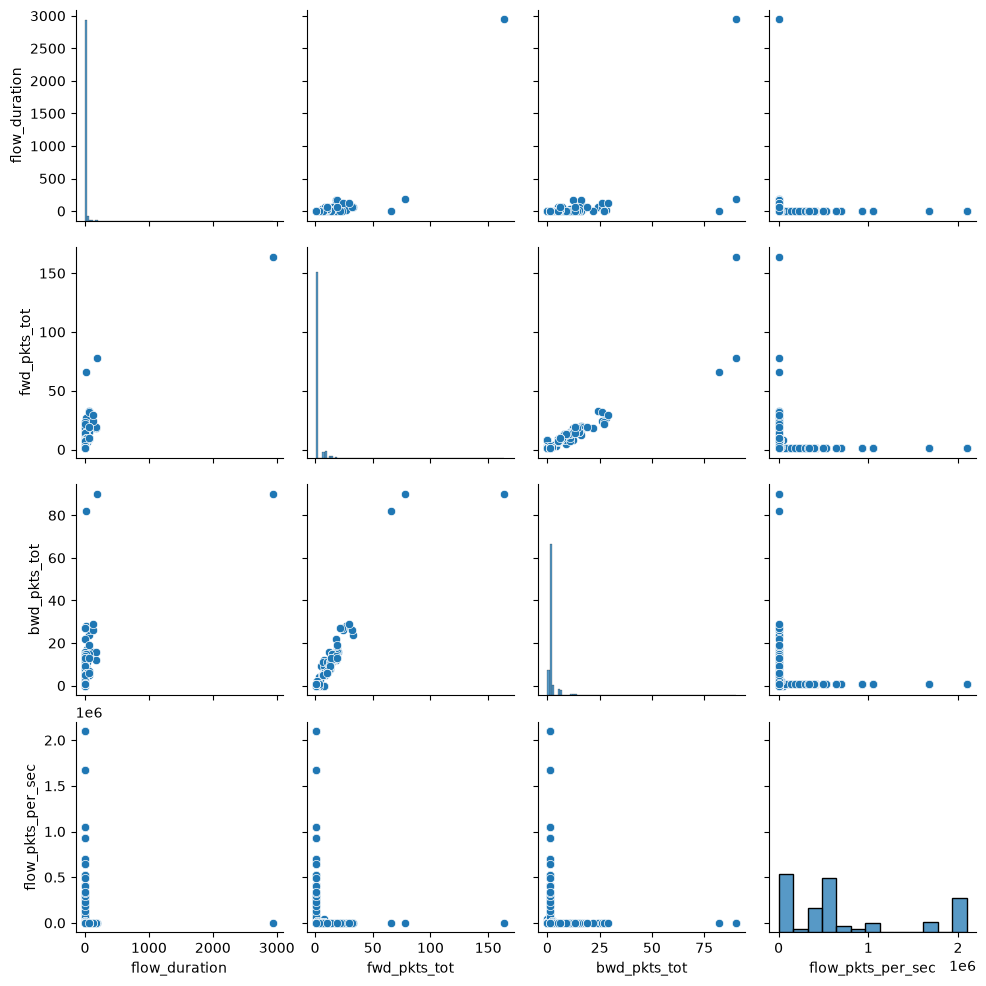

In [21]:
sns.pairplot(sample)

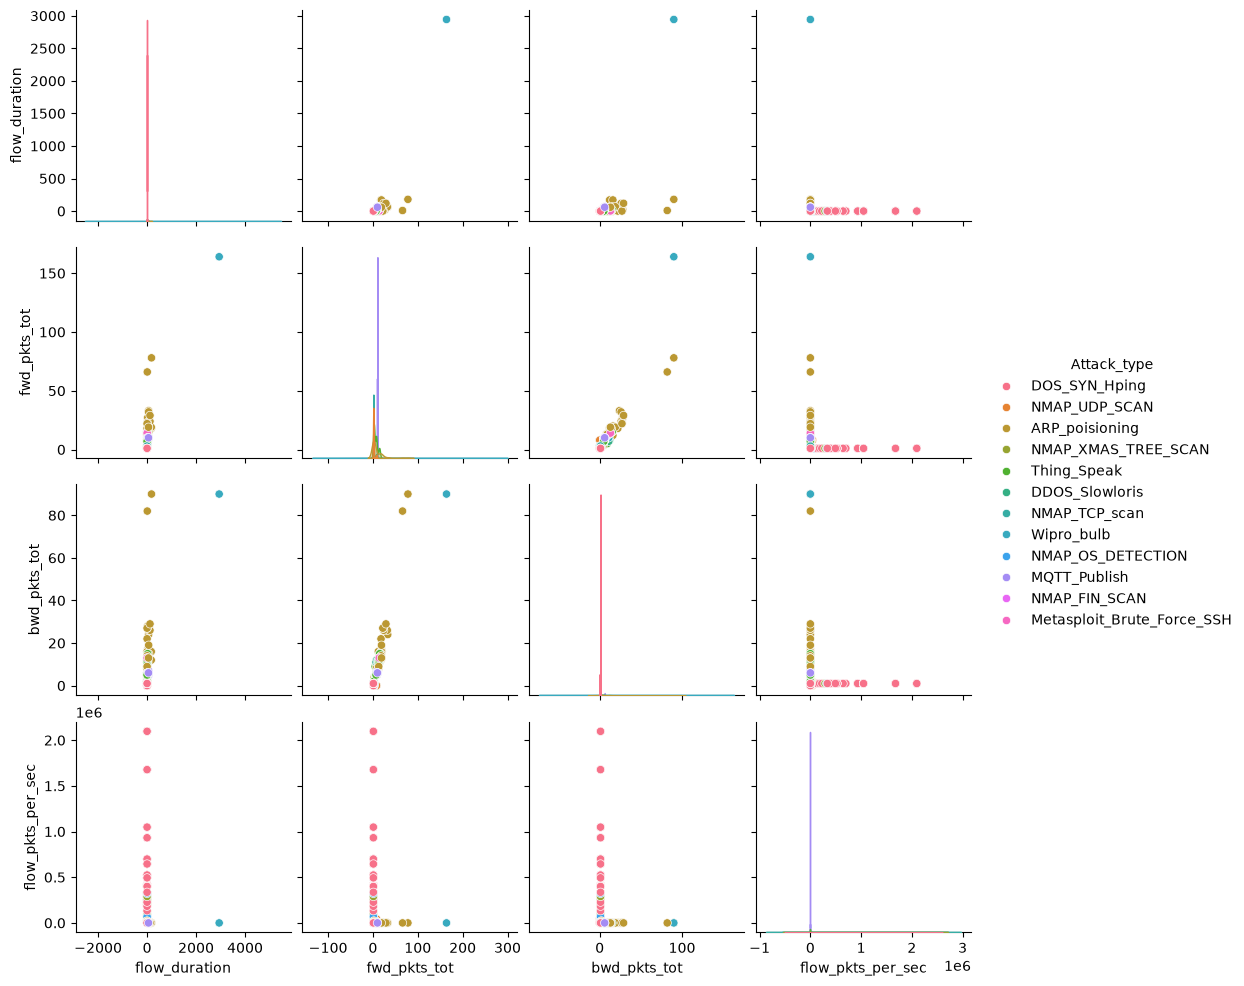

In [22]:
sns.pairplot(sample,hue="Attack_type")

### Nhận xét:

- Các biến số tập trung gần 0 và có đuôi dài, khó tách lớp chỉ bằng mắt ở thang tuyến tính.
- Một số lớp (ví dụ `DOS_SYN_Hping`, các kiểu `NMAP_*`) gần như chỉ có luồng rất ngắn.

## **Heatmap**

Biểu diễn ma trận tương quan bằng màu sắc.

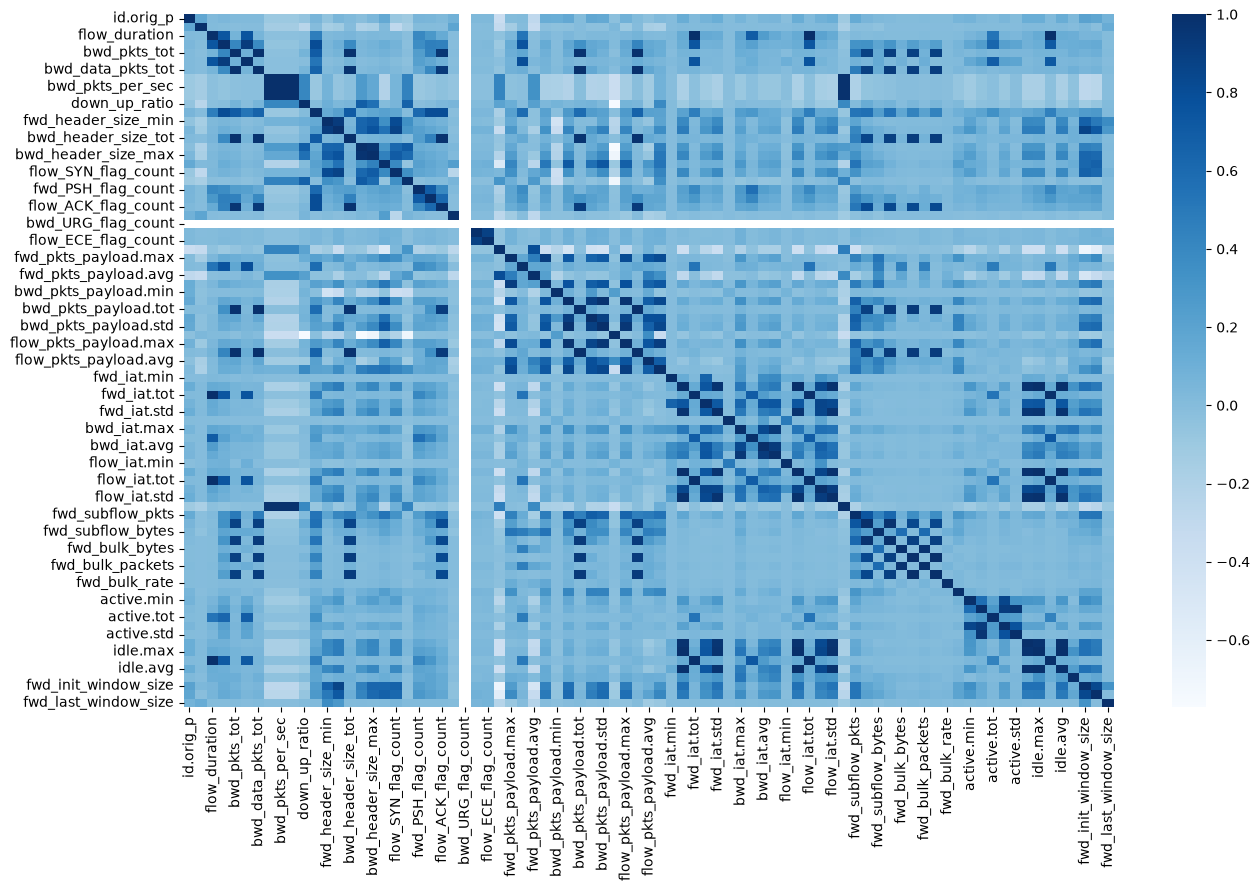

In [23]:
fig = plt.figure(figsize = (15,9))
sns.heatmap(df.corr(numeric_only=True), cmap='Blues');

- Có **75 cặp cột tương quan > 0,9** → nhiều đặc trưng dư thừa, có thể loại bớt hoặc dùng PCA.
- Cột `bwd_URG_flag_count` chỉ có một giá trị (hằng số) → ô trắng trên heatmap, nên loại bỏ.

**Histogram – phân phối các biến**

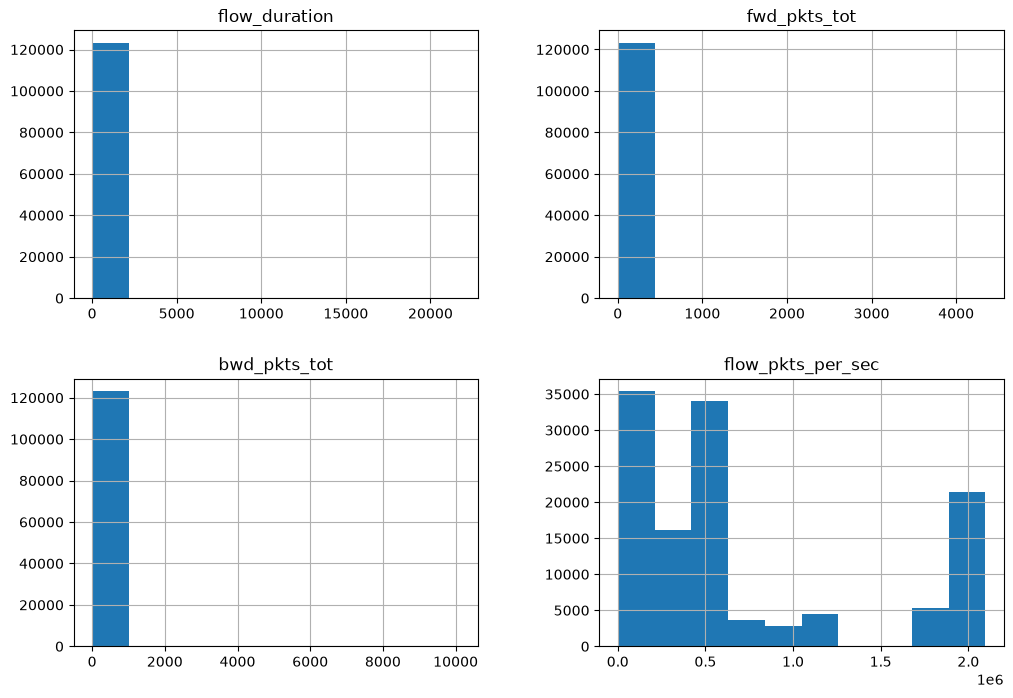

In [24]:
df[cols].hist(figsize=(12, 8));

**Boxplot và violin – `flow_duration` theo từng loại tấn công**

Nhận xét: các kiểu quét `NMAP_*` và `DOS_SYN_Hping` có thời lượng ≈ 0, còn `MQTT_Publish` (~44 s) và `DDOS_Slowloris` (~20 s) có luồng dài nhất (theo trung vị) → `flow_duration` là đặc trưng hữu ích để phân lớp.

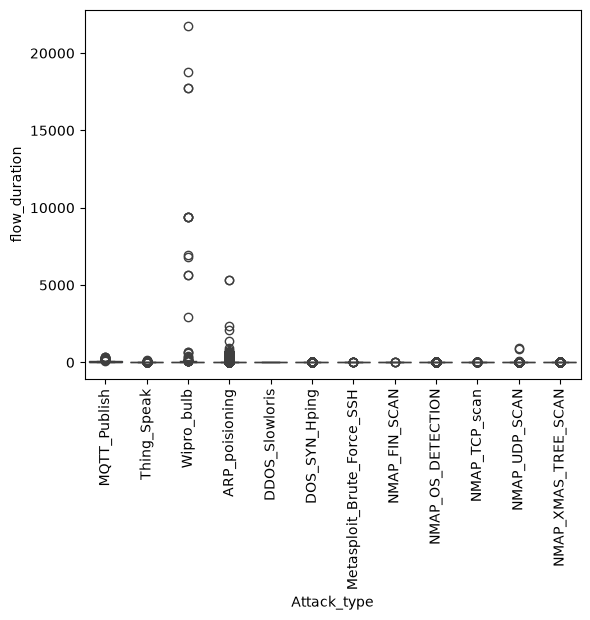

In [25]:
sns.boxplot(x='Attack_type', y='flow_duration', data=df)
plt.xticks(rotation=90);

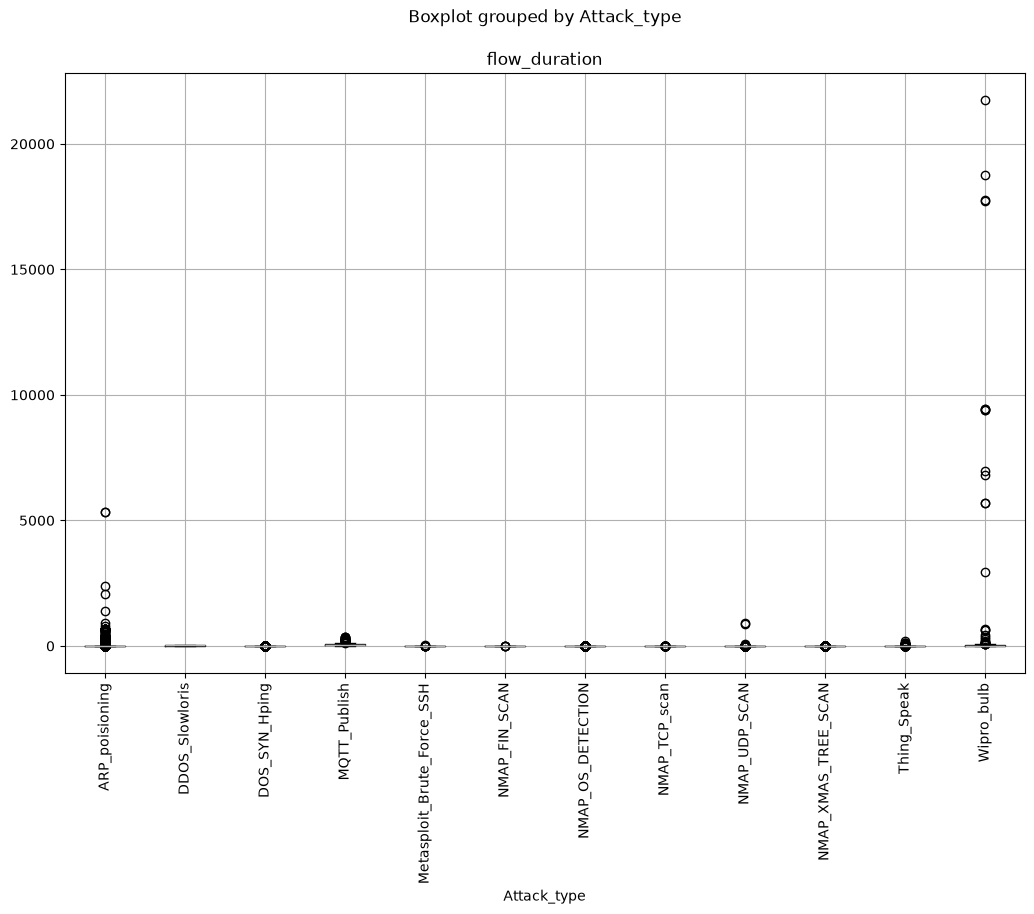

In [26]:
df.boxplot(column='flow_duration', by='Attack_type', figsize=(12, 8), rot=90);

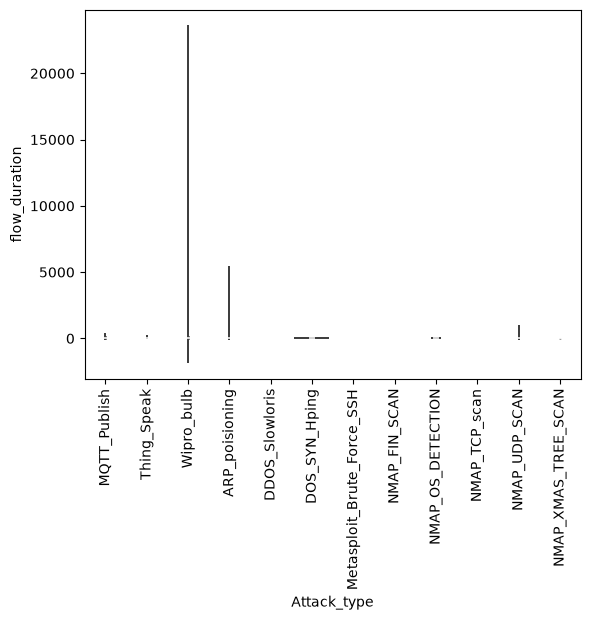

In [27]:
sns.violinplot(x='Attack_type', y='flow_duration', data=df)
plt.xticks(rotation=90);